# 01 - Exploratory Data Analysis
Breast Cancer Wisconsin (Diagnostic). Educational use only; not a clinical tool.

In [1]:
import sys; sys.path.append('..')
import warnings; warnings.filterwarnings('ignore')
%matplotlib inline
import matplotlib.pyplot as plt, pandas as pd, numpy as np
from src.data_loader import load_data, split_data
X, y = load_data()
print(X.shape)
X.head()

(569, 30)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


## Class balance
Malignant is the positive class (1).

malignant
benign       357
malignant    212
Name: count, dtype: int64 
 malignant
benign       0.627
malignant    0.373
Name: count, dtype: float64


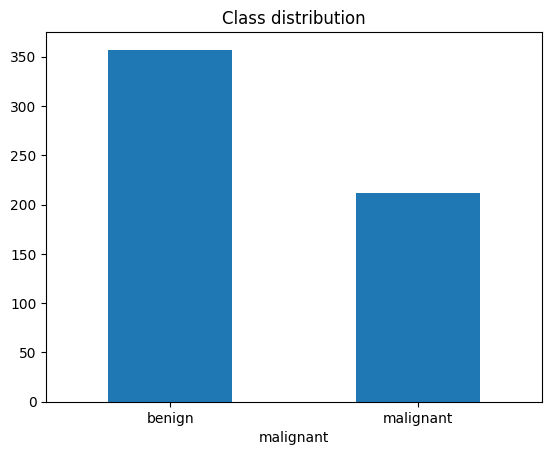

In [2]:
counts = y.map({0:'benign',1:'malignant'}).value_counts()
print(counts, '\n', (counts/len(y)).round(3))
counts.plot.bar(rot=0, title='Class distribution'); plt.show()

## Data quality

In [3]:
print('Missing values:', int(X.isna().sum().sum()))
print('Duplicate rows:', int(X.duplicated().sum()))
X.describe().T.round(3).head(10)

Missing values: 0
Duplicate rows: 0


,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127,3.524,6.981,11.700,13.370,15.780,28.110
mean texture,569.0,19.290,4.301,9.710,16.170,18.840,21.800,39.280
mean perimeter,569.0,91.969,24.299,43.790,75.170,86.240,104.100,188.500
mean area,569.0,654.889,351.914,143.500,420.300,551.100,782.700,2501.000
mean smoothness,569.0,0.096,0.014,0.053,0.086,0.096,0.105,0.163
mean compactness,569.0,0.104,0.053,0.019,0.065,0.093,0.130,0.345
mean concavity,569.0,0.089,0.080,0.000,0.030,0.062,0.131,0.427
mean concave points,569.0,0.049,0.039,0.000,0.020,0.034,0.074,0.201
mean symmetry,569.0,0.181,0.027,0.106,0.162,0.179,0.196,0.304
mean fractal dimension,569.0,0.063,0.007,0.050,0.058,0.062,0.066,0.097


## Feature distributions by class
The `worst` and `mean` size/shape features separate the classes strongly.

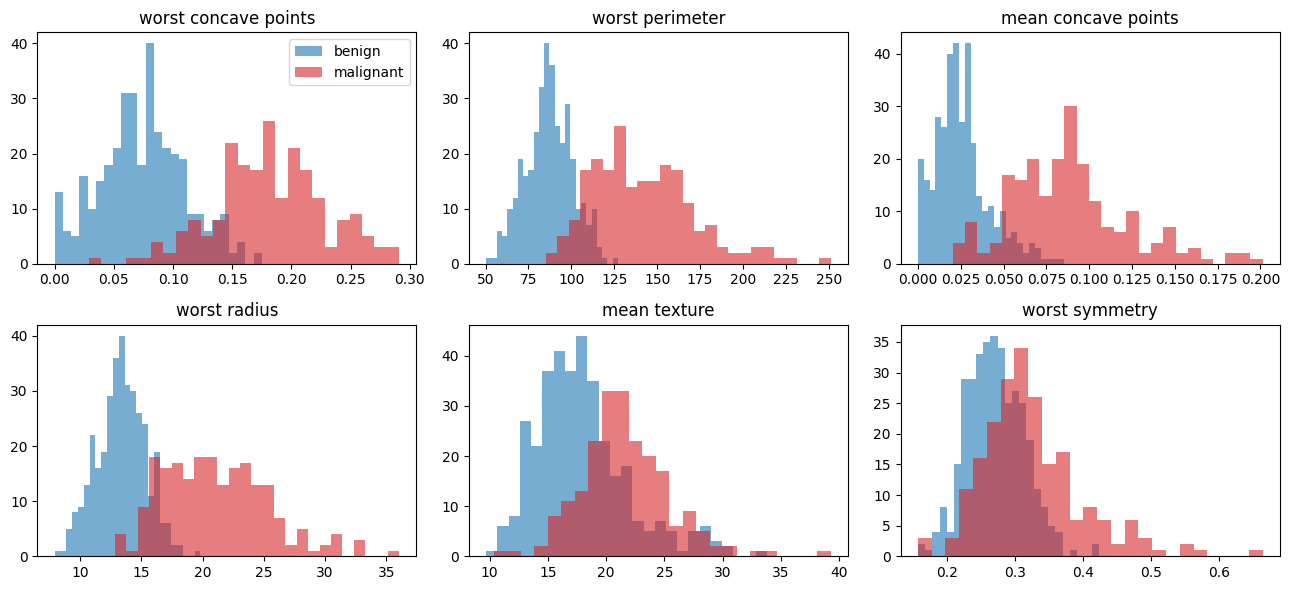

In [4]:
top = ['worst concave points','worst perimeter','mean concave points','worst radius','mean texture','worst symmetry']
fig, axes = plt.subplots(2,3, figsize=(13,6))
for ax, f in zip(axes.ravel(), top):
    for cls, c in [(0,'tab:blue'),(1,'tab:red')]:
        ax.hist(X.loc[y==cls, f], bins=25, alpha=.6, color=c, label=['benign','malignant'][cls])
    ax.set_title(f)
axes[0,0].legend(); plt.tight_layout(); plt.show()

## Correlation structure
Radius, perimeter and area are almost perfectly correlated, so the data is highly redundant. This matters for interpreting feature importance and for linear models.

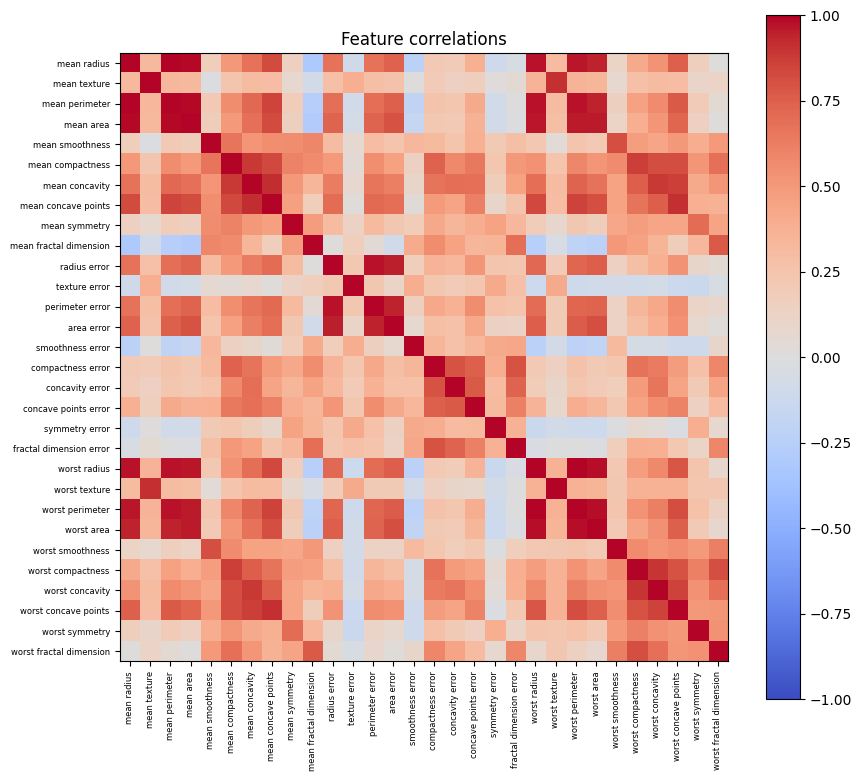

Feature pairs with |r| > 0.95: 15


In [5]:
corr = X.corr()
fig, ax = plt.subplots(figsize=(9,8))
im = ax.imshow(corr, cmap='coolwarm', vmin=-1, vmax=1)
ax.set_xticks(range(30)); ax.set_yticks(range(30))
ax.set_xticklabels(X.columns, rotation=90, fontsize=6); ax.set_yticklabels(X.columns, fontsize=6)
plt.colorbar(im); plt.title('Feature correlations'); plt.tight_layout(); plt.show()
high = corr.where(np.triu(np.ones(corr.shape), 1).astype(bool)).stack()
print('Feature pairs with |r| > 0.95:', int((high.abs()>0.95).sum()))

## Takeaways
- 37% malignant: moderately imbalanced, so accuracy alone is misleading; use PR-AUC and recall.
- No missing values; 30 strongly correlated features.
- Small dataset (569 rows), so evaluation estimates will be noisy.